# Walking Accessability Anaysis from Buildings to Supermarkets in Duisburg/Germany (OpenStreetMap)

This project makes it possible to establish an understanding of the walking distances for every residential building existing within the corresponding city boundary to its nearest supermarket. It derives the residential buildings, supermarkets and the cities pedestrian network, cleans and manages OMS-derived datasets, links the nearest nodes of each building and supermarket and computes the shortest-path distances with the help of the walking graph.

**Scope and Limitations**

- Derives all residential buildings, supermarkets and pedestrian network of Duisburg.
- Cleans and manages OSM-datasets.
- links buildings and supermarkets to nearest nodes and computes shortest-path distances with walking graph.
- Compares the districts with the average distance to supermarkets and creates a ranking.

# 1 Libraries and Imports

In [2]:
from pyrosm import OSM, get_data
import geopandas as gpd
import pandas as pd
import networkx as nx
import osmnx as ox
import pathlib
import pandas
from itertools import product
import matplotlib.pyplot as plt
import numpy
from matplotlib.colors import LinearSegmentedColormap

# 2 Configuration of Project Directory

In [3]:
# Projects Directory 
NOTEBOOK_PATH = pathlib.Path().resolve()
DIRECTORY = NOTEBOOK_PATH / "data"

# Output Directory 
OUTPUT = NOTEBOOK_PATH / "outputs"

# 3 Download walking network graph (OSM)

In [4]:
# Pull name for Nominatim OSM 
Place_name = "Duisburg, North Rhine-Westphalia, Germany"

# Download the the walking street network for Duisburg
G = ox.graph_from_place(Place_name, network_type="walk", simplify=True)

# IMPORTANT: Reproject the graph to local metric coordinate system for adequate distance calculation 
G_projected = ox.project_graph(G)

# Convert the graph into geodataframe for nodes and edges
nodes, edges = ox.graph_to_gdfs(G_projected)


print(f"Nodes: {len(nodes):,}")
print(f"Edges: {len(edges):,}")

Nodes: 43,751
Edges: 120,604


In [5]:
# Check the coordinate reference system for nodes and edges
print("Nodes CRS:", nodes.crs)
print("Edges CRS:", edges.crs)

Nodes CRS: EPSG:32632
Edges CRS: EPSG:32632


# 4 Visualize walking network 

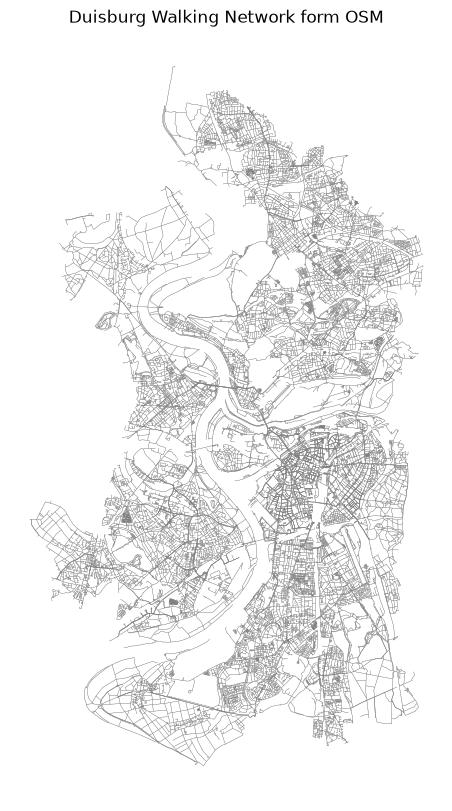

In [6]:
fig, ax = plt.subplots(figsize=(10,10))
edges.plot(ax=ax, color = "gray", linewidth=0.2) 
ax.set_title("Duisburg Walking Network form OSM")
ax.axis("off")

output_name = OUTPUT / "Duisburg_walking_network_osm.png"
plt.savefig(output_name, dpi= 1000, bbox_inches = "tight")
plt.show()

# 5 Extraction of OSM data using OSMnX and Pyrosm

It is important to define the exact boundary of the area of interest. If necessary cross-check this step with OSM-nominatim and the official geoportal of the city of interest. 

<br>

**Disclaimer**: The precise definition of residential buildings - and furthermore what tags to use - changes from country to country. Here addtional cross-checking is advised. 

In [25]:
# Define the boundary of Duisburg
duisburg_boundary = ox.geocode_to_gdf(Place_name)
duisburg_boundary = duisburg_boundary.geometry.iloc[0]

# Pyrosm is a rapid OSM parser, wich makes it interesting for large datasets
osm = OSM(get_data("Duisburg", directory= DIRECTORY), bounding_box= duisburg_boundary)

# Define the OSM tags for residential buildings only
residential_list_buildings = {"building":[
    "apartments", "barracks", "bungalow", "detached", "annexe", "dormitory", "hotel", "house", "residential", "semidetached_house", "house", "terrace"
]}
building_duisburg = osm.get_buildings(custom_filter=residential_list_buildings)

supermarket = {"shop" : ["supermarket"]}
supermarket_duisburg = osm.get_pois(custom_filter = supermarket)

# 6 Manage and clean the datasets

Unfortunately, there is no uniform practice how to name the supermarkets. For example: The supermarket chain "ALDI SÜD" is listed as aldi, ALDI, ALDI SÜD, Aldi and so on. In order to clean this up I decided to align each name so no accidents are made and have a much better overview. 

In [8]:
supermarket_duisburg["name"].unique()

<StringArray>
[                'Netto City',      'Netto Marken-Discount',
    'Edeka Center Angerbogen',                   'Aldi Süd',
           'Edeka Center EKZ',    'Edeka Center Marktforum',
           'Burc Frischmarkt',                      'Norma',
              'Edeka Laudage',                 'Edeka Luft',
                      'Penny',                       'REWE',
             'Rewe Corzilius',                   'Kaufland',
        'Penny Sternbuschweg',                       'Depo',
               'Pro Biomarkt',                     'Globus',
        'Yasmeen Frischmarkt',             'Bereket Market',
            'Esma Supermarkt',       'Hofladen Enninghorst',
                    'Go Asia',                      'EDEKA',
              'EDEKA Daniels',                'Sila Market',
          'Ming's Asia Markt',             'Edeka Jucknies',
                       'Rewe',                      'Edeka',
                 'Cham Markt',                   'Pro Vita',
          

In [9]:
edeka_mask = supermarket_duisburg["name"].str.lower().str.startswith("edeka", na=False)
aldi_mask = supermarket_duisburg["name"].str.lower().str.startswith("aldi", na=False)
rewe_mask = supermarket_duisburg["name"].str.lower().str.startswith("rewe", na=False)
penny_mask = supermarket_duisburg["name"].str.lower().str.startswith("penny", na=False)
netto_mask = supermarket_duisburg["name"].str.lower().str.startswith("netto", na=False)
lidl_mask = supermarket_duisburg["name"].str.lower().str.startswith("lidl", na=False)

supermarket_duisburg.loc[edeka_mask, "name"] = "Edeka"
supermarket_duisburg.loc[aldi_mask, "name"] = "Aldi"
supermarket_duisburg.loc[rewe_mask, "name"] = "Rewe"
supermarket_duisburg.loc[penny_mask, "name"] = "Penny"
supermarket_duisburg.loc[netto_mask, "name"] = "Netto"
supermarket_duisburg.loc[lidl_mask, "name"] = "Lidl"

In [10]:
# How many residential buildings and supermarkets exists in Duisburg?
print(building_duisburg.geometry.geom_type.value_counts())
print(supermarket_duisburg.geometry.geom_type.value_counts())

Polygon    41948
Name: count, dtype: int64
Polygon    80
Point      71
Name: count, dtype: int64


## 6.1 Check and change geometry types 

For some reason supermarkets are not always listed as polygons. Fortunately, this should not result in an issue in the next step. We want to convert all polygons of buildings and supermarkets in representative points. In order to calculate the shortest distance of each building to its nearest supermarket, it is necessary to find the closest node of each building and supermarket and connect those.  

In [11]:
building_duisburg_point = building_duisburg.copy()
supermarket_duisburg_point = supermarket_duisburg.copy()

building_duisburg_point["geometry"] = building_duisburg_point.geometry.representative_point()
supermarket_duisburg_point["geometry"] = supermarket_duisburg_point.geometry.representative_point()

# Project supermarket and buildings points to same crs as the walking network. 
building_duisburg_point = building_duisburg_point.to_crs(nodes.crs)
supermarket_duisburg_point = supermarket_duisburg_point.to_crs(nodes.crs)

# All polygons are now transformed into points. 
print(building_duisburg_point.geometry.geom_type.value_counts())
print(supermarket_duisburg_point.geometry.geom_type.value_counts())


print(building_duisburg_point.columns)

Point    41948
Name: count, dtype: int64
Point    151
Name: count, dtype: int64
Index(['addr:city', 'addr:country', 'addr:housenumber', 'addr:housename',
       'addr:postcode', 'addr:place', 'addr:street', 'email', 'name',
       'opening_hours', 'operator', 'phone', 'ref', 'visible', 'website',
       'building', 'amenity', 'building:flats', 'building:levels',
       'building:material', 'building:use', 'craft', 'height',
       'internet_access', 'office', 'shop', 'source', 'start_date', 'id',
       'timestamp', 'version', 'tags', 'osm_type', 'geometry', 'changeset'],
      dtype='str')


## 6.3 Only useful columns

In [12]:
# For better overview, keep only useful columns
building_duisburg_useful_col = [
    "id",
    "addr:housenumber",
    "addr:postcode",
    "addr:street",
    "geometry"
]

supermarket_duisburg_useful_col = [
    "id",
    "name",
    "geometry"
]

building_duisburg_point_clean = building_duisburg_point[building_duisburg_useful_col].copy()
supermarket_duisburg_point_clean = supermarket_duisburg_point[supermarket_duisburg_useful_col].copy()


In [13]:
building_duisburg_point_clean.head()

,id,addr:housenumber,addr:postcode,addr:street,geometry
0,25071786,2,47051,Opernplatz,POINT (345115.354 5700505.684)
1,25092209,"15,17,19",47051,Königstraße,POINT (344788.732 5700405.103)
2,25308429,243,47228,Römerstraße,POINT (337839.001 5699813.689)
3,25308430,249,47228,Römerstraße,POINT (337829.717 5699838.833)
4,25308748,257,47228,Römerstraße,POINT (337872.75 5699878.829)


In [14]:
supermarket_duisburg_point_clean.head()

,id,name,geometry
0,209226489,Netto,POINT (346761.782 5695702.479)
1,214043979,Netto,POINT (345341.064 5692624.358)
2,243457549,Edeka,POINT (343284.144 5692456.453)
3,271942242,Aldi,POINT (345410.199 5693449.226)
4,365346509,Edeka,POINT (340715.217 5698989.183)


## 6.4 Plot buildings and supermarket

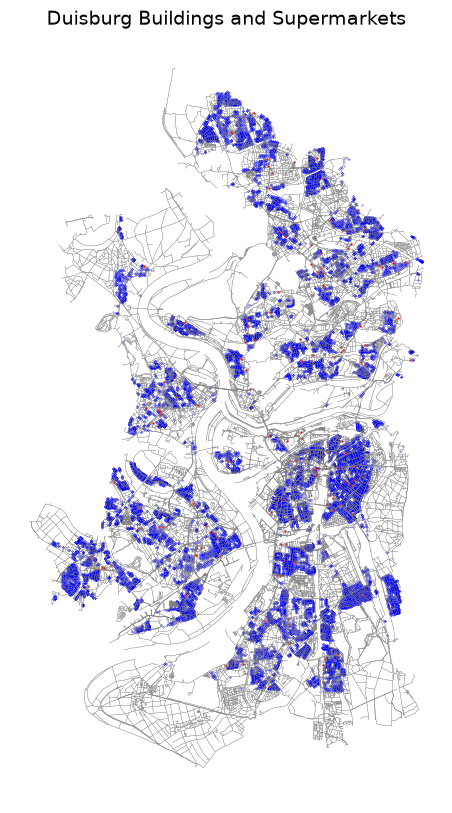

In [15]:
fig, ax = plt.subplots(figsize=(10,10))

edges.plot(ax = ax, color= "gray", linewidth=0.2)
building_duisburg_point_clean.plot(ax = ax, color= "blue", markersize = 0.05)
supermarket_duisburg_point_clean.plot(ax=ax, color = "red", markersize = 0.5)
ax.axis("off")

ax.set_title("Duisburg Buildings and Supermarkets", fontsize = 14)
output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000.png"

plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")


# 7 Link buildings and supermarkets to nearest network node

In [16]:
# Since a pedestrian can walk in both directions, an undirected version of the walking graph is necessary 
G_access = ox.convert.to_undirected(G_projected)

building_duisburg_point_clean = building_duisburg_point_clean.copy()

# Find the nearest node for each building
building_duisburg_point_clean["nearest_node"] = ox.distance.nearest_nodes(
    G_access, 
    X= building_duisburg_point_clean.geometry.x,
    Y= building_duisburg_point_clean.geometry.y
    )

supermarket_duisburg_point_clean = supermarket_duisburg_point_clean.copy()

# Find the nearest node for each supermarket
supermarket_duisburg_point_clean["nearest_node"] = ox.distance.nearest_nodes(
    G_access,
    X = supermarket_duisburg_point_clean.geometry.x,
    Y = supermarket_duisburg_point_clean.geometry.y
)

source_nodes_buildings = building_duisburg_point_clean["nearest_node"].tolist()
source_nodes_supermarket = supermarket_duisburg_point_clean["nearest_node"].tolist()

In [17]:
building_duisburg_point_clean.head()

,id,addr:housenumber,addr:postcode,addr:street,geometry,nearest_node
0,25071786,2,47051,Opernplatz,POINT (345115.354 5700505.684),563357000
1,25092209,"15,17,19",47051,Königstraße,POINT (344788.732 5700405.103),1118989441
2,25308429,243,47228,Römerstraße,POINT (337839.001 5699813.689),275672242
3,25308430,249,47228,Römerstraße,POINT (337829.717 5699838.833),275672245
4,25308748,257,47228,Römerstraße,POINT (337872.75 5699878.829),85471036


In [18]:
supermarket_duisburg_point_clean.head()

,id,name,geometry,nearest_node
0,209226489,Netto,POINT (346761.782 5695702.479),3168251749
1,214043979,Netto,POINT (345341.064 5692624.358),1345797225
2,243457549,Edeka,POINT (343284.144 5692456.453),2334849759
3,271942242,Aldi,POINT (345410.199 5693449.226),271942248
4,365346509,Edeka,POINT (340715.217 5698989.183),458884175


# 8 Compute network accessibility

Utilizing `nx.multi_source_dijkstra()` the shortest walking distance and path from every network node to the nearest supermarket is calculated in meter.

In [19]:
# distance_to_supermarket = nx.multi_source_dijkstra_path_length(
#     G_access,
#     source_nodes_supermarket,
#     weight = "length"
# )

# # Attach the results to the nodes GeoDataFrame
# nodes_access_supermarket = nodes.copy()
# nodes_access_supermarket["distance_to_supermarket"] = nodes_access_supermarket.index.map(distance_to_supermarket)

# nodes_access_supermarket["distance_to_supermarket"].describe()


In [23]:
dist, paths = nx.multi_source_dijkstra(G_access, source_nodes_supermarket, weight="length")

# Form dictionary with the name of supermarket and its nearest node
node_to_name = (supermarket_duisburg_point_clean.drop_duplicates("nearest_node").set_index("nearest_node")["name"].to_dict())

# Extract the starting node of the path to connect with target
nearest_node = {node:path[0] for node, path in paths.items()}

# Add distances to the buildings GeoDataFrame depending on the the match of ID
building_duisburg_point_clean["dist_to_supermarket"] = building_duisburg_point_clean["nearest_node"].map(dist)

# Add nearest_node_supermarket to the buildings GeoDataFrame depending on the the match of ID
building_duisburg_point_clean["nearest_node_supermarket"] = building_duisburg_point_clean["nearest_node"].map(nearest_node)

# Add nearest_node_supermarket to the buildings GeoDataFrame depending on the the match of ID
building_duisburg_point_clean["name_supermarket"] = building_duisburg_point_clean["nearest_node_supermarket"].map(node_to_name)

print(building_duisburg_point_clean["dist_to_supermarket"].describe())

count    41948.000000
mean       682.850222
std        490.416212
min          0.000000
25%        365.116652
50%        555.564900
75%        849.099357
max       5138.330731
Name: dist_to_supermarket, dtype: float64


Citizens in Duisburg need to walk 683 meters on average to the nearest supermarket.

# 9 Accessibility Categories 

To improve iterpretability the results are categorized into 4 groups:

1. 0m - 500m
2. 500m - 1000m
3. 1000m - 1500m
4. 1500m +

In [36]:
bins = [0, 500, 1000, 1500, float("inf")]
labels = ["0–500 m", "500-1000 m", "1000-1500 m", "1500+ m"]

# Cut the building-to-supermarket-distances into the four categories
building_duisburg_point_clean["dist_to_supermarket_cut"] = pd.cut(
    building_duisburg_point_clean["dist_to_supermarket"],
    bins = bins,
    labels= labels,
    include_lowest=True
)

label_summary = building_duisburg_point_clean["dist_to_supermarket_cut"].value_counts().sort_index()
label_share = (label_summary / len(building_duisburg_point_clean) * 100).round(1)

pd.DataFrame({
    "Count of Buildings": label_summary,
    "Share of Percent": label_share
})

,Count of Buildings,Share of Percent
dist_to_supermarket_cut,,
0–500 m,18295,43.6
500-1000 m,16566,39.5
1000-1500 m,4005,9.5
1500+ m,3082,7.3


Most buildings are located within 500 meters of the nearest supermarket. Nearly 40% are situated between 500 and 1,000 meters away, approximately 10% are between 1,000 and 1,500 meters, and 7% are more than 1,500 meters away.

# 10 Visualization

## 10.1 Accessibillity map with `type(buildings)` = points

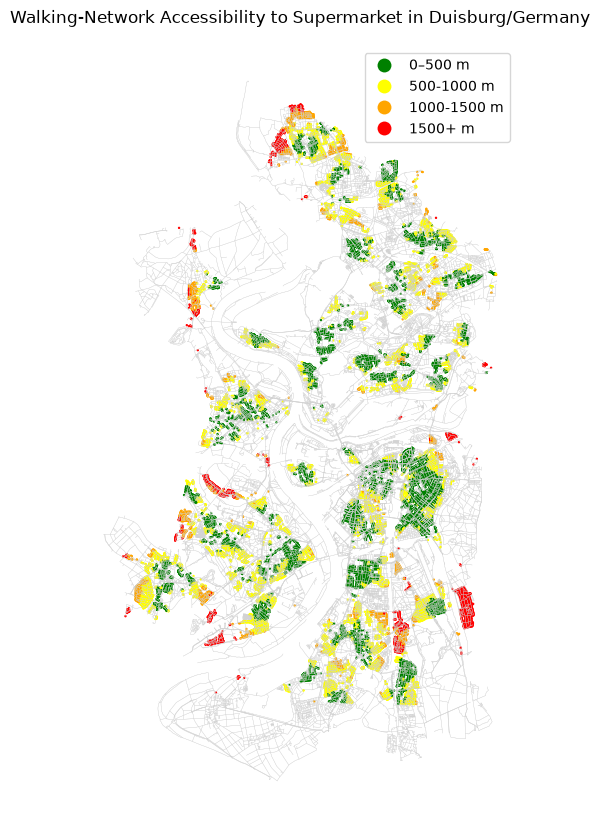

In [47]:
# Color scheme for better visualization
cmap = LinearSegmentedColormap.from_list("gyor", ["green", "yellow", "orange", "red"])

fig, ax = plt.subplots(figsize = (10,10))

# Network in the backround
edges.plot(
    ax=ax,
    linewidth=0.2, 
    color = "lightgray"
)

# Buildings as geometry = points 
building_duisburg_point_clean.plot(
    ax = ax, 
    column = "dist_to_supermarket_cut", 
    cmap= cmap, 
    markersize = 0.5, 
    legend = True
)

ax.set_title("Walking-Network Accessibility to Supermarket in Duisburg/Germany")
ax.set_axis_off()

output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000_nearest_distance.png"

plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")

## 10.2 Accessibillity map with `type(buildings)` = polygons

This has no advantage over the method with points. I was just interested in converting them into the original geometry type.  

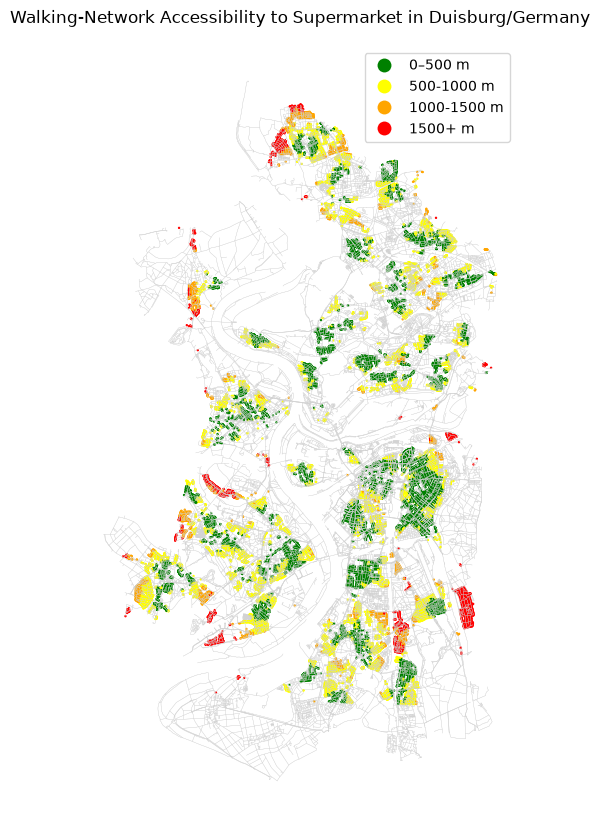

In [56]:
building_duisburg_endproduct = building_duisburg_point_clean.copy()
building_duisburg_endproduct["geometry"] = building_duisburg.geometry.to_crs(nodes.crs)


fig, ax = plt.subplots(figsize = (10,10))

# Network in the backround
edges.plot(
    ax=ax,
    linewidth=0.2, 
    color = "lightgray"
)

# Buildings as geometry = points 
building_duisburg_point_clean.plot(
    ax = ax, 
    column = "dist_to_supermarket_cut", 
    cmap= cmap, 
    markersize = 0.5, 
    legend = True
)

ax.set_title("Walking-Network Accessibility to Supermarket in Duisburg/Germany")
ax.set_axis_off()

output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000_nearest_distance_GPOLYGON.png"
plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")

# 11 Accesssibility Analyis per Districts

Duisburg has seven districts. It would be interesting to conduct this analyis at the district level and compare between them. 

<br>

Unfortunately, the extraction of the correct districts proves to be difficult. A commen way to get hold of those administrative boundaries is with the tag `admin_level : 9`. In order to extract the correct districts a manual intermediate step is necessary. 

In [71]:
admin_level_9 = ox.features_from_place(
    Place_name,
    tags={"admin_level" : "9"},
)

# Define only the correct districts that should be extracted. 
stadtteile_duisburg = [
    "Rheinhausen",
    "Homberg/Ruhrort/Baerl",
    "Walsum",
    "Hamborn",
    "Meiderich/Beeck",
    "Duisburg-Mitte",
    "Duisburg-Süd"
]

admin_level_9 = admin_level_9[admin_level_9["name"].isin(stadtteile_duisburg)].to_crs(nodes.crs)

admin_level_9


geometry  \
element  id                                                           
relation 1350280  POLYGON ((335044.472 5697648.038, 335040.342 5...   
         1350346  POLYGON ((335365.377 5708489.831, 335624.492 5...   
         1357886  POLYGON ((339634.222 5714646.222, 339737.664 5...   
         1357922  POLYGON ((341308.636 5707463.142, 341701.652 5...   
         1357936  POLYGON ((340145.807 5704702.906, 339776.03 57...   
         1357946  POLYGON ((340961.561 5701100.463, 341149.98 57...   
         1357947  POLYGON ((336974.909 5691342.308, 336877.609 5...   

                 admin_level        boundary source source:ref  \
element  id                                                      
relation 1350280           9  administrative    NaN        NaN   
         1350346           9  administrative    NaN        NaN   
         1357886           9  administrative    NaN        NaN   
         1357922           9  administrative    NaN        NaN   
         1357936           9  administrative    NaN        NaN   
         1357946           9  administrative    NaN        NaN   
         1357947           9  administrative    NaN        NaN   

                                   name      type population  ref  \
element  id                                                         
relation 1350280            Rheinhausen  boundary        NaN  600   
         1350346  Homberg/Ruhrort/Baerl  boundary        NaN  400   
         1357886                 Walsum  boundary        NaN  100   
         1357922                Hamborn  boundary        NaN  200   
         1357936        Meiderich/Beeck  boundary        NaN  300   
         1357946         Duisburg-Mitte  boundary        NaN  500   
         1357947           Duisburg-Süd  boundary        NaN  700   

                 source:population  wikidata  \
element  id                                    
relation 1350280               NaN   Q469928   
         1350346               NaN   Q881325   
         1357886               NaN   Q449632   
         1357922               NaN   Q512233   
         1357936               NaN  Q5764545   
         1357946               NaN   Q317314   
         1357947               NaN   Q884445   

                                          wikipedia  name:prefix FIXME  \
element  id                                                              
relation 1350280            de:Duisburg-Rheinhausen          NaN   NaN   
         1350346  de:Duisburg-Homberg/Ruhrort/Baerl  Stadtbezirk   NaN   
         1357886                 de:Duisburg-Walsum  Stadtbezirk   NaN   
         1357922                         de:Hamborn  Stadtbezirk   NaN   
         1357936        de:Duisburg-Meiderich/Beeck  Stadtbezirk   NaN   
         1357946                  de:Duisburg-Mitte  Stadtbezirk   NaN   
         1357947                    de:Duisburg-Süd  Stadtbezirk   NaN   

                 alt_name  
element  id                
relation 1350280      NaN  
         1350346      NaN  
         1357886      NaN  
         1357922      NaN  
         1357936      NaN  
         1357946      NaN  
         1357947      NaN

In [64]:
# Spatially join building-gdf and district-gdf
dist_supermarket_district = gpd.sjoin(building_duisburg_point_clean, admin_level_9, how = "left" )[["name", "geometry", "dist_to_supermarket", "name_supermarket"]]

In [72]:
# Calculate the mean distance of every building to the nearest supermarket per district and sort the values
dist_supermarket_district_mean = dist_supermarket_district.groupby("name")["dist_to_supermarket"].mean().sort_values()

admin_level_9 = admin_level_9.merge(
    dist_supermarket_district_mean,
    left_on="name",  
    right_index=True,  
    how="left",  
)
print(dist_supermarket_district_mean)

name
Duisburg-Mitte           464.423872
Meiderich/Beeck          494.320245
Hamborn                  578.256871
Homberg/Ruhrort/Baerl    747.236852
Rheinhausen              771.195096
Walsum                   829.131013
Duisburg-Süd             918.111419
Name: dist_to_supermarket, dtype: float64


## 11.1 Visualization of Accessibility Analyis per Districts

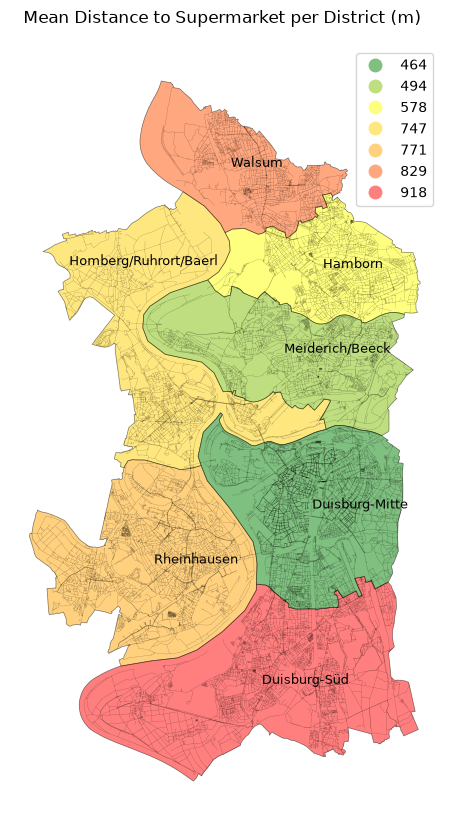

In [83]:
admin_level_9["dist_to_supermarket"] = admin_level_9["dist_to_supermarket"].round(0).astype(int)


fig, ax = plt.subplots(figsize = (10,10))

# Plot the district
admin_level_9.plot(
    ax=ax, 
    column= "dist_to_supermarket", 
    categorical=True, 
    edgecolor= "black", 
    linewidth=0.5, 
    cmap=cmap, 
    alpha = 0.5, 
    legend = True
)

# Plot the district names. Since the district Homberg/Ruhrort/Baerl 
# turned out to be to big for the polygon, the function changes the 
# position of the text. 

def change_pos_HomRuhBae (x):
    if x["name"] == "Homberg/Ruhrort/Baerl":
        ax.annotate(
            text = x["name"],
            xy = x.geometry.centroid.coords[0],
            xytext = (339000, 5708000),
            fontsize = 9,
            ha = "center"
        )
    
    else:
        ax.annotate( 
        text = x["name"],
        xy = x.geometry.centroid.coords[0],
        fontsize = 9
        )

admin_level_9.apply(change_pos_HomRuhBae, axis = 1)

edges.plot(ax=ax,linewidth=0.2, color = "black", alpha = 0.2) 
ax.set_title("Mean Distance to Supermarket per District (m) ")

legend_kwds={'title': 'Average distance to supermarket (m)'}

ax.set_axis_off()

output_path = OUTPUT / "duisburg_buildings_and_supermarkets1000_nearest_distance_cityDistricts.png"

plt.savefig(output_path, dpi = 1000, bbox_inches = "tight")